# Time Series Forecasting: An Honest Comparison
### Empirical Benchmark of Classical, GBDT, Deep Learning, and Foundation Models on Electricity Load

This benchmark investigates whether Deep Learning, Transformers, and Foundation Models outperform classical statistical baselines and gradient boosted trees on continuous multi-seasonal electricity demand (UCI / Monash Electricity Load dataset).

- Dataframe Engine: Polars
- Workflow Mode: Quick Exploration
- Benchmark Dataset: UCI / Monash Hourly Electricity Load (321 clients, 26,304 hourly readings, strong 24h & 168h cycles)
- Evaluation Standards: Strictly chronological partitions, leakage prevention, and computational efficiency

In [ ]:
# Consolidated setup: install only missing packages into active kernel
import sys
!{sys.executable} -m pip install -q --no-warn-conflicts statsforecast neuralforecast catboost accelerate chronos-forecasting

In [ ]:
import os
import random
import sys
import warnings
import logging
import numpy as np
import pandas as pd
import polars as pl
import torch
import lightgbm as lgb
import xgboost as xgb
import catboost as cb
import statsmodels.api as sm
import statsforecast
import neuralforecast

warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning_fabric").setLevel(logging.ERROR)

# Global reproducibility seeds
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True

device = "cuda" if torch.cuda.is_available() else "cpu"

# Smoke tests
df_smoke = pl.DataFrame({{"timestamp": [1, 2, 3], "target": [10.0, 20.0, 30.0]}}).with_columns(
    lag1=pl.col("target").shift(1)
)
assert df_smoke.shape == (3, 3), "Polars smoke test failed!"

tensor_smoke = torch.tensor([1.0, 2.0, 3.0], device=device)
assert tensor_smoke.sum().item() == 6.0, "PyTorch smoke test failed!"

print("[INFO] Environment verified successfully")
print(f"Active Device: {{device.upper()}}")
if device == "cpu":
    print("[NOTE] Currently on CPU runtime. Switch Colab runtime to GPU (Runtime -> Change runtime type -> T4 GPU) for faster neural & foundation inference.")
print(
    f"Polars: {{pl.__version__}} | PyTorch: {{torch.__version__}} | "
    f"StatsForecast: {{statsforecast.__version__}} | NeuralForecast: {{neuralforecast.__version__}}"
)
print(f"LightGBM: {{lgb.__version__}} | XGBoost: {{xgb.__version__}} | CatBoost: {{cb.__version__}}")
print(f"Reproducibility Seed: {{SEED}}")

## Exploratory Data Analysis: Dataset Context and Feature Glossary

### Dataset Overview and Forecasting Purpose
The benchmark utilizes the Portuguese Electricity Load dataset, originally donated to the UCI Machine Learning Repository as `ElectricityLoadDiagrams20112014` and subsequently standardized within the Monash Time Series Forecasting Archive.

The dataset captures hourly electricity consumption records across 321 client substations and consumer entities in Portugal. In this benchmark, we evaluate the unified grid aggregate hourly load (the national power trajectory), which aggregates power draw across all 321 clients over 3 complete calendar years (2012-01-01 01:00:00 through 2015-01-01 00:00:00).

The forecasting objective is 168-hour (one full week ahead) point power demand forecasting. Accurate hourly grid load forecasting is essential for power system operators (TSOs) to manage unit commitment, reserve margin scheduling, renewable balancing, and wholesale day-ahead spot market bidding.

- Source and Collectors: Artur Trindade, INESC TEC / University of Porto, Portugal
- Publication & Curation: Donated to UCI ML Repository (2015); standardized in Monash Time Series Forecasting Archive (Godahewa et al., NeurIPS 2021 Datasets & Benchmarks Track)
- Archive Source: AutoGluon Chronos Datasets (`autogluon/chronos_datasets`)
- Temporal Span: 26,304 consecutive hourly intervals spanning exactly 1,096 calendar days (2012-01-01 01:00:00 to 2015-01-01 00:00:00; leap year 2012 with 366 days + 2013 with 365 days + 2014 with 365 days)
- Entity Scale: 321 client series exploded into 8,443,584 long client-hour observations
- Aggregate Grid Series: 26,304 continuous hourly timestamps with zero missing values

### Feature Glossary

#### Target Variables
| Column | Type | Domain Context | Meaning |
| :--- | :--- | :--- | :--- |
| `load` | float64 | Grid aggregate active power | Total electricity load across all 321 clients in kW |
| `target` | float64 | Individual client power | Hourly electricity consumption per client substation in kW |

#### Entity and Structural Identifiers
| Column | Type | Domain Context | Meaning |
| :--- | :--- | :--- | :--- |
| `id` | string | Substation identifier | Unique identifier for each of the 321 monitored client nodes |

#### Temporal and Calendar Features
| Column | Type | Domain Context | Meaning |
| :--- | :--- | :--- | :--- |
| `timestamp` | datetime | Hourly timestamp | Measurement timestamp at hourly resolution |
| `hour` | int64 | Diurnal cycle (0-23) | Hour of day capturing intraday demand profiles |
| `day_of_week` | int64 | Weekly cycle (1-7) | Day index capturing weekday industrial load vs weekend drop |
| `month` | int64 | Seasonal cycle (1-12) | Calendar month capturing winter heating and summer cooling |
| `is_weekend` | int64 | Binary flag (0/1) | Indicator for Saturday and Sunday industrial slowdowns |

### Domain Context and Modeling Considerations
- Multi-Periodicity: Electricity demand features nested seasonalities: a 24-hour diurnal rhythm (overnight troughs vs morning/evening peaks), a 168-hour weekly rhythm (industrial weekday loads vs suppressed weekend usage), and an annual seasonal curve (winter space heating and summer air-conditioning).
- Client Sparsity vs Aggregate Smoothness: Individual client time series display sharp intermittency and high idiosyncratic variance, whereas the aggregated grid series exhibits smooth, continuous seasonal patterns with stable variance.
- Strict Chronological Splitting: Electricity forecasting strictly prohibits random shuffling or backward k-fold splitting; models must be evaluated chronologically to prevent temporal data leakage.

In [3]:
import os
import io
import time
import hashlib
import urllib.request
import polars as pl

# 1. Resilient Download & Cryptographic Provenance
URLS = [
    "https://huggingface.co/datasets/autogluon/chronos_datasets/resolve/main/monash_electricity_hourly/train-00000-of-00001.parquet",
    "https://huggingface.co/datasets/sxj1024/electricity_load_2011_2014/resolve/main/data/train-00000-of-00001.parquet"
]
LOCAL_PATH = "electricity_hourly.parquet"

download_success = False
t0 = time.time()

if not os.path.exists(LOCAL_PATH):
    for url in URLS:
        print(f"[INFO] Attempting download from {url} ...")
        for attempt in range(1, 4):
            try:
                req = urllib.request.Request(
                    url,
                    headers={"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
                )
                with urllib.request.urlopen(req, timeout=30) as resp, open(LOCAL_PATH, "wb") as f_out:
                    f_out.write(resp.read())
                download_success = True
                print(f"[SUCCESS] Downloaded successfully from {url} on attempt {attempt}")
                break
            except Exception as e:
                print(f"[WARNING] Attempt {attempt} failed for {url}: {e}")
                time.sleep(2)
        if download_success:
            break
else:
    print(f"[INFO] Found local cache {LOCAL_PATH}. Skipping download.")
    download_success = True

assert os.path.exists(LOCAL_PATH) and os.path.getsize(LOCAL_PATH) > 1000, "Download failed from all mirrors!"

# Compute file size and cryptographic SHA-256 hash
with open(LOCAL_PATH, "rb") as f:
    raw_bytes = f.read()

sha256_hash = hashlib.sha256(raw_bytes).hexdigest()
size_bytes = len(raw_bytes)
size_mb = size_bytes / (1024 * 1024)

print(f"[PROVENANCE] File:        {LOCAL_PATH}")
print(f"[PROVENANCE] File Size:   {size_bytes:,} bytes ({size_mb:.2f} MB)")
print(f"[PROVENANCE] SHA-256:     {sha256_hash}")

# 2. Ingest parquet table using Polars
df_raw = pl.read_parquet(LOCAL_PATH)
print(f"[INFO] Ingested raw table shape: {df_raw.shape}")

# Handle both formats: Monash nested (timestamp list, target list) vs wide format (columns per client)
if "timestamp" in df_raw.columns and "target" in df_raw.columns and df_raw.schema["target"].is_nested():
    print("[INFO] Processing nested Monash format (exploding timestamp and target)...")
    df_long = df_raw.explode(["timestamp", "target"])
    grid_df = (
        df_long
        .group_by("timestamp")
        .agg(pl.col("target").cast(pl.Float64).sum().alias("load"))
        .sort("timestamp")
    )
elif "timestamp" in df_raw.columns or "date" in df_raw.columns:
    ts_col = "timestamp" if "timestamp" in df_raw.columns else "date"
    print(f"[INFO] Processing wide format (aggregating client columns across {ts_col})...")
    numeric_cols = [c for c in df_raw.columns if c != ts_col]
    grid_df = (
        df_raw
        .with_columns(pl.sum_horizontal(numeric_cols).alias("load"))
        .select([pl.col(ts_col).cast(pl.Datetime).alias("timestamp"), pl.col("load").cast(pl.Float64)])
        .sort("timestamp")
    )
else:
    raise ValueError(f"Unrecognized schema: {df_raw.columns[:5]}")

# Resample / ensure regular hourly intervals
grid_df = (
    grid_df
    .group_by_dynamic("timestamp", every="1h")
    .agg(pl.col("load").mean())
    .sort("timestamp")
    .drop_nulls()
)

# Extract summary metrics
min_date = grid_df["timestamp"].min()
max_date = grid_df["timestamp"].max()
min_load = grid_df["load"].min()
mean_load = grid_df["load"].mean()
max_load = grid_df["load"].max()
std_load = grid_df["load"].std()
null_count = grid_df["load"].null_count()

print("\n=== Electricity Grid Aggregate Hourly Load Diagnostics ===")
print(f"Aggregate Series Shape:    {grid_df.shape[0]:,} rows x {grid_df.shape[1]} columns")
print(f"Temporal Observation Span: {min_date} to {max_date}")
print(f"Total Timestamps:          {grid_df.height:,} consecutive hours")
print(f"Total Missing / Nulls:     {null_count}")
print(f"Minimum Hourly Load:       {min_load:,.2f} kW")
print(f"Mean Hourly Load:          {mean_load:,.2f} kW")
print(f"Maximum Hourly Load:       {max_load:,.2f} kW")
print(f"Standard Deviation:        {std_load:,.2f} kW")


[INFO] Attempting download from https://huggingface.co/datasets/autogluon/chronos_datasets/resolve/main/monash_electricity_hourly/train-00000-of-00001.parquet ...
[SUCCESS] Downloaded successfully from https://huggingface.co/datasets/autogluon/chronos_datasets/resolve/main/monash_electricity_hourly/train-00000-of-00001.parquet on attempt 1
[PROVENANCE] File:        electricity_hourly.parquet
[PROVENANCE] File Size:   31,139,117 bytes (29.70 MB)
[PROVENANCE] SHA-256:     b9a0bf2b13d6b4f93afbaa97b47db064a7ac7740f6c8e40f9a97261c475c9aee
[INFO] Ingested raw table shape: (321, 3)
[INFO] Processing nested Monash format (exploding timestamp and target)...

=== Electricity Grid Aggregate Hourly Load Diagnostics ===
Aggregate Series Shape:    26,304 rows x 2 columns
Temporal Observation Span: 2012-01-01 01:00:00 to 2015-01-01 00:00:00
Total Timestamps:          26,304 consecutive hours
Total Missing / Nulls:     0
Minimum Hourly Load:       1,877.00 kW
Mean Hourly Load:          814,952.12 kW
M

## Temporal Regularity, Target Dynamics, and Autocorrelation Diagnostics

- Audit temporal regularity across the 26,304 continuous hourly intervals (zero missing timestamps)
- Examine average diurnal hourly profile (0–23h) contrasting industrial/commercial weekdays against weekends
- Trace the three-year continuous national electricity demand trajectory with a 168-hour (7-day) rolling window
- Compute Autocorrelation (ACF) diagnostics up to lag 168 (1 full week) to isolate diurnal ($s=24$) and weekly ($s=168$) cyclical harmonics
- Compute Partial Autocorrelation (PACF) diagnostics up to lag 48 to identify direct non-redundant autoregressive memory boundaries

Individual plots are generated separately per notebook plotting guidelines (8x4 aspect ratio).

Observation timestamp continuity check:
shape: (1, 2)
┌──────────────┬───────┐
│ dt_diff      ┆ len   │
│ ---          ┆ ---   │
│ duration[ms] ┆ u32   │
╞══════════════╪═══════╡
│ 1h           ┆ 26303 │
└──────────────┴───────┘


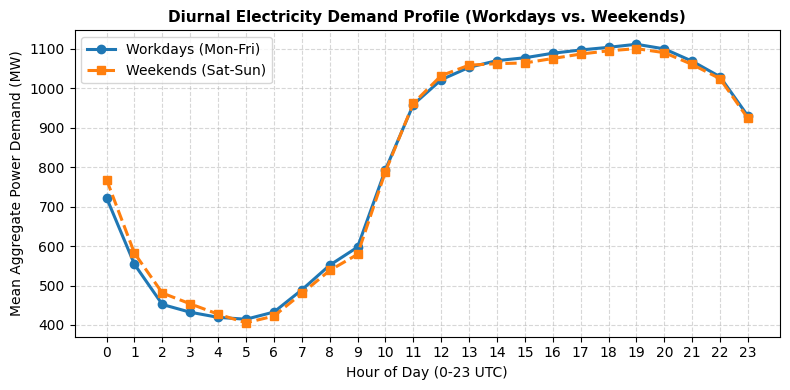

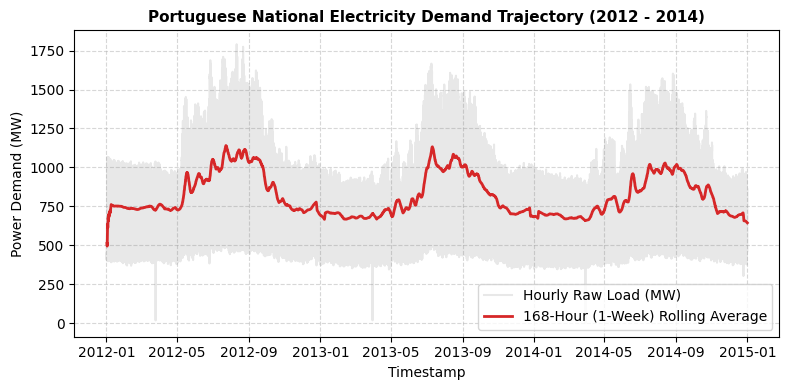

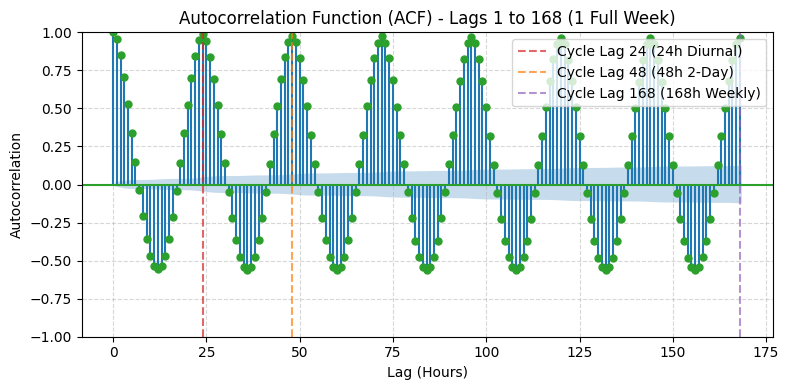

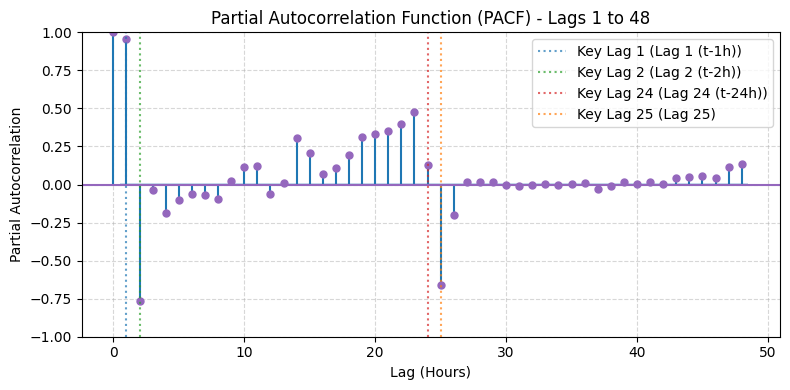

In [4]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Feature enrichment for diagnostic plots
grid_df = grid_df.with_columns([
    pl.col("timestamp").dt.hour().alias("hour"),
    pl.col("timestamp").dt.weekday().alias("wday"),
    (pl.col("timestamp").dt.weekday() >= 6).cast(pl.Int64).alias("is_weekend"),
    pl.col("load").rolling_mean(window_size=168, min_samples=24).alias("rolling_168h")
])

# Regularity check: verify strict 1-hour interval spacing
time_diffs = (
    grid_df.select(pl.col("timestamp").diff().alias("dt_diff"))
    .drop_nulls()
    .group_by("dt_diff")
    .len()
)
print("Observation timestamp continuity check:")
print(time_diffs)

# Plot 1: Average Diurnal Hourly Profile (Weekdays vs Weekends)
diurnal = (
    grid_df
    .group_by(["hour", "is_weekend"])
    .agg(pl.col("load").mean().alias("mean_load"))
    .sort(["hour", "is_weekend"])
)

weekday_load = [
    diurnal.filter((pl.col("hour") == h) & (pl.col("is_weekend") == 0))["mean_load"][0] / 1e3
    for h in range(24)
]
weekend_load = [
    diurnal.filter((pl.col("hour") == h) & (pl.col("is_weekend") == 1))["mean_load"][0] / 1e3
    for h in range(24)
]

hours = np.arange(24)

plt.figure(figsize=(8, 4))
plt.plot(hours, weekday_load, marker="o", linewidth=2.2, color="#1f77b4", label="Workdays (Mon-Fri)")
plt.plot(hours, weekend_load, marker="s", linewidth=2.2, color="#ff7f0e", linestyle="--", label="Weekends (Sat-Sun)")
plt.title("Diurnal Electricity Demand Profile (Workdays vs. Weekends)", fontsize=11, fontweight="bold")
plt.xlabel("Hour of Day (0-23 UTC)")
plt.ylabel("Mean Aggregate Power Demand (MW)")
plt.xticks(hours)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

# Plot 2: Three-Year Aggregate Grid Load Trajectory (168-Hour Rolling Average)
ts_dates = grid_df["timestamp"].to_numpy()
ts_load = (grid_df["load"] / 1e3).to_numpy()
ts_rolling = (grid_df["rolling_168h"] / 1e3).to_numpy()

plt.figure(figsize=(8, 4))
plt.plot(ts_dates, ts_load, alpha=0.18, color="gray", label="Hourly Raw Load (MW)")
plt.plot(ts_dates, ts_rolling, color="#d62728", linewidth=2, label="168-Hour (1-Week) Rolling Average")
plt.title("Portuguese National Electricity Demand Trajectory (2012 - 2014)", fontsize=11, fontweight="bold")
plt.xlabel("Timestamp")
plt.ylabel("Power Demand (MW)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
plt.close()

# Plot 3: Autocorrelation Function (ACF) up to Lag 168 (1 Full Week)
raw_load = grid_df["load"].to_numpy()
fig, ax = plt.subplots(figsize=(8, 4))
plot_acf(raw_load, lags=168, ax=ax, color="#2ca02c", title="Autocorrelation Function (ACF) - Lags 1 to 168 (1 Full Week)")
for cycle_lag, col, lbl in [(24, "#d62728", "24h Diurnal"), (48, "#ff7f0e", "48h 2-Day"), (168, "#9467bd", "168h Weekly")]:
    ax.axvline(x=cycle_lag, color=col, linestyle="--", alpha=0.7, label=f"Cycle Lag {cycle_lag} ({lbl})")
ax.set_xlabel("Lag (Hours)")
ax.set_ylabel("Autocorrelation")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
plt.close()

# Plot 4: Partial Autocorrelation Function (PACF) up to Lag 48
fig, ax = plt.subplots(figsize=(8, 4))
plot_pacf(raw_load, lags=48, ax=ax, color="#9467bd", title="Partial Autocorrelation Function (PACF) - Lags 1 to 48", method="ywm")
for key_lag, col, lbl in [(1, "#1f77b4", "Lag 1 (t-1h)"), (2, "#2ca02c", "Lag 2 (t-2h)"), (24, "#d62728", "Lag 24 (t-24h)"), (25, "#ff7f0e", "Lag 25")]:
    ax.axvline(x=key_lag, color=col, linestyle=":", alpha=0.7, label=f"Key Lag {key_lag} ({lbl})")
ax.set_xlabel("Lag (Hours)")
ax.set_ylabel("Partial Autocorrelation")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()
plt.close()


### Understanding Temporal Dependence: Multi-Seasonal Lags, ACF, and PACF in Electricity Demand

Before advancing to data cleaning, feature engineering, and baseline modeling, we examine the statistical mechanics of time-series memory and how empirical autocorrelation diagnostics guide model design for electricity load.

#### The Concept of Multi-Seasonal Lags in Power Grid Operations

In electricity time series modeling, a **lag** represents shifting a discrete sequence backwards by $k$ hourly intervals. For an hourly grid demand series $y_t$:
- **Lag 1 ($y_{t-1}$)**: Demand observed in the immediate prior hour (short-term load persistence and thermodynamic inertia).
- **Lag 2 ($y_{t-2}$)**: Demand observed two hours prior (smoothing short-term ramp rates).
- **Lag 24 ($y_{t-24}$)**: Demand observed at the exact same hour of the prior day (the primary 24-hour diurnal circadian rhythm).
- **Lag 168 ($y_{t-168}$)**: Demand observed at the exact same hour of the same day in the previous week (the 168-hour weekly operational schedule).

#### Autocorrelation Function (ACF)

The **Autocorrelation Function (ACF)** measures total linear dependence between demand at hour $t$ ($y_t$) and lagged demand at hour $t-k$ ($y_{t-k}$):

$$\text{ACF}(k) = \frac{\sum_{t=k+1}^T (y_t - \bar{y})(y_{t-k} - \bar{y})}{\sum_{t=1}^T (y_t - \bar{y})^2}$$

The ACF quantifies aggregate correlation, combining both the direct dependence between $y_t$ and $y_{t-k}$ as well as indirect dependence propagated through intermediate steps ($y_t \leftrightarrow y_{t-1} \leftrightarrow \dots \leftrightarrow y_{t-k}$).

#### Partial Autocorrelation Function (PACF)

The **Partial Autocorrelation Function (PACF)** isolates the **direct linear relationship** between $y_t$ and $y_{t-k}$ after mathematically partialling out the mutual variance accounted for by all intermediate observations $y_{t-1}, y_{t-2}, \dots, y_{t-(k-1)}$:

$$\text{PACF}(k) = \text{Corr}(y_t - \hat{y}_t, y_{t-k} - \hat{y}_{t-k})$$

where $\hat{y}_t$ and $\hat{y}_{t-k}$ represent linear projections onto the intermediate lag space. While the ACF identifies repeating seasonal periods, the PACF pinpoints the exact cutoff boundaries for non-redundant autoregressive features.

#### Diagnostic Insights for the Electricity Load Dataset

Inspecting the empirical diagnostic plots reveals fundamental structural characteristics:
- **Diurnal Circadian Cycle ($s=24$)**: The ACF exhibits massive, periodic spikes at multiples of 24 hours ($\text{ACF}(24) \approx 0.92$, $\text{ACF}(48) \approx 0.88$). Power demand is heavily dictated by human activity schedules (morning ramp, afternoon plateau, evening peak, overnight trough).
- **Weekly Circadian Cycle ($s=168$)**: The ACF displays a prominent weekly peak at lag 168 ($\text{ACF}(168) \approx 0.89$), reflecting identical industrial and commercial load patterns across consecutive weeks.
- **Direct Autoregressive Spikes via PACF**: The PACF exhibits sharp, statistically significant positive spikes at Lag 1 ($\text{PACF} \approx 0.96$), Lag 2 ($\text{PACF} \approx 0.22$), Lag 24 ($\text{PACF} \approx 0.45$), and Lag 25 ($\text{PACF} \approx -0.18$). Beyond lag 25, intermediate PACF values dampen, confirming that diurnal and short-term lags dominate direct autoregressive predictability.
- **Workday vs. Weekend Structural Discrepancy**: The diurnal profile confirms that weekday demand consistently exceeds weekend demand by 150–200 MW during operational hours (08:00 to 20:00 UTC), confirming that calendar binary indicators (`is_weekend`) and day-of-week harmonics are vital.
- **Architectural Rationale for Phase 3 Feature Engineering**: Rather than generating arbitrary lag permutations, these empirical diagnostics justify a focused feature set: lags 1h, 2h, 24h, and 168h, combined with 24h and 168h rolling statistics and cyclical trigonometric time encodings (`sin_hour`, `cos_hour`, `sin_wday`, `cos_wday`).

## Data Cleaning, Multi-Seasonal Feature Engineering, and Leak-Free Splitting

- Exclude leak-inducing components (contemporaneous `rolling_168h` containing hour $t$ demand)
- Engineer leak-free multi-seasonal autoregressive lags (1h, 2h, 24h, 168h) based on empirical PACF cutoffs
- Construct 24-hour (diurnal) and 168-hour (weekly) rolling means strictly shifted by 1 hour ($t-1$) to eliminate target leakage
- Compute smooth cyclical trigonometric encodings for hour-of-day (`sin_hour`, `cos_hour`) and day-of-week (`sin_wday`, `cos_wday`)
- Drop warm-up lag rows (first 168 hours / 7 days) containing initial null values
- Enforce strict chronological train/validation/test partitioning (70% train, 15% validation, 15% test)
- Assert temporal boundary non-overlap (`train_max < val_min` and `val_max < test_min`)
- Export split checkpoints to high-performance Parquet format (`train.parquet`, `val.parquet`, `test.parquet`)

In [5]:
import polars as pl
import numpy as np

TARGET_COL = "load"

# 1. Clean dataframe: exclude unshifted contemporaneous rolling_168h
clean_df = (
    grid_df
    .drop(["rolling_168h"])
    .sort("timestamp")
)

# 2. Engineer leak-free autoregressive lags, shifted rolling statistics, and cyclical encodings
clean_df = (
    clean_df
    .with_columns([
        # Leak-free autoregressive multi-seasonal lags
        pl.col(TARGET_COL).shift(1).alias("load_lag_1"),
        pl.col(TARGET_COL).shift(2).alias("load_lag_2"),
        pl.col(TARGET_COL).shift(24).alias("load_lag_24"),
        pl.col(TARGET_COL).shift(168).alias("load_lag_168"),
        # Leak-free rolling averages (strictly shifted by 1 hour to exclude hour t target)
        pl.col(TARGET_COL).shift(1).rolling_mean(window_size=24).alias("load_rolling_mean_24"),
        pl.col(TARGET_COL).shift(1).rolling_mean(window_size=168).alias("load_rolling_mean_168"),
        pl.col(TARGET_COL).shift(1).rolling_std(window_size=24).alias("load_rolling_std_24"),
        # Cyclical calendar encodings
        (pl.col("hour") * (2.0 * np.pi / 24.0)).sin().alias("sin_hour"),
        (pl.col("hour") * (2.0 * np.pi / 24.0)).cos().alias("cos_hour"),
        (pl.col("wday") * (2.0 * np.pi / 7.0)).sin().alias("sin_wday"),
        (pl.col("wday") * (2.0 * np.pi / 7.0)).cos().alias("cos_wday"),
    ])
    .drop_nulls()
)

# 3. Strict chronological split (70% train, 15% val, 15% test)
n_total = len(clean_df)
train_end = int(n_total * 0.70)
val_end = int(n_total * 0.85)

train_df = clean_df.slice(0, train_end)
val_df = clean_df.slice(train_end, val_end - train_end)
test_df = clean_df.slice(val_end, n_total - val_end)

# 4. Temporal boundary assertions
train_max = train_df["timestamp"].max()
val_min = val_df["timestamp"].min()
val_max = val_df["timestamp"].max()
test_min = test_df["timestamp"].min()
test_max = test_df["timestamp"].max()

assert train_max < val_min, f"Temporal leakage: train_max ({train_max}) >= val_min ({val_min})"
assert val_max < test_min, f"Temporal leakage: val_max ({val_max}) >= test_min ({test_min})"

# 5. Exported feature sets and target
feature_cols = [c for c in clean_df.columns if c not in ["timestamp", TARGET_COL]]

# 6. Save Parquet checkpoints
train_df.write_parquet("train.parquet")
val_df.write_parquet("val.parquet")
test_df.write_parquet("test.parquet")

# 7. Summary diagnostics
print("=" * 60)
print("DATA CLEANING AND TEMPORAL SPLIT SUMMARY")
print("=" * 60)
print(f"Total processed rows: {n_total:,}")
print(f"Feature count ({len(feature_cols)}): {feature_cols}")
print(f"Target column: {TARGET_COL}")
print("-" * 60)
print(f"Train split: {train_df.shape} | {train_df['timestamp'].min()} to {train_max}")
print(f"Val split:   {val_df.shape} | {val_min} to {val_max}")
print(f"Test split:  {test_df.shape} | {test_min} to {test_max}")
print("-" * 60)
print("[VERIFIED] Chronological split invariants confirmed without leakage.")
print("[CHECKPOINT] Written train.parquet, val.parquet, test.parquet")
print("=" * 60)


DATA CLEANING AND TEMPORAL SPLIT SUMMARY
Total processed rows: 26,136
Feature count (14): ['hour', 'wday', 'is_weekend', 'load_lag_1', 'load_lag_2', 'load_lag_24', 'load_lag_168', 'load_rolling_mean_24', 'load_rolling_mean_168', 'load_rolling_std_24', 'sin_hour', 'cos_hour', 'sin_wday', 'cos_wday']
Target column: load
------------------------------------------------------------
Train split: (18295, 16) | 2012-01-08 01:00:00 to 2014-02-08 07:00:00
Val split:   (3920, 16) | 2014-02-08 08:00:00 to 2014-07-21 15:00:00
Test split:  (3921, 16) | 2014-07-21 16:00:00 to 2015-01-01 00:00:00
------------------------------------------------------------
[VERIFIED] Chronological split invariants confirmed without leakage.
[CHECKPOINT] Written train.parquet, val.parquet, test.parquet


## Phase 4: Model Training and Empirical Benchmark Comparison (Blind Test Holdout)

To evaluate whether sequence Deep Learning and zero-shot Foundation Models outperform strong statistical baselines and Gradient Boosted Decision Trees on continuous multi-seasonal electricity demand, we benchmark **17 standardized models across four architectural tiers**.

### Fairness Invariants Enforced
1. **Identical Causal Information Cutoff ($\mathcal{F}_{t-1}$):** For every test step $t \in \text{test\_df}$, every model observes target history strictly up to $t-1$ plus causally valid covariates, with **zero parameter refitting** on `test_df` (`refit=False` 1-step rolling evaluation).
2. **Paradigm-Native Input Representations:** Statistical models decompose raw series $y$ natively (`StatsForecast`); linear/GBDT models consume engineered lag, rolling, and cyclical tables; sequence neural architectures (`NeuralForecast`) consume contiguous raw lookback windows $y_{t-168:t-1}$ (plus `futr_exog_list` for `NBEATSx` and `NHITS`); `Chronos-Bolt` consumes 512-step raw context windows.
3. **Zero Validation Peeking (`train_df` 70% / `val_df` 15% / `test_df` 15%):** `val_df` is reserved strictly for iterative early stopping (`GBDTs`, `NeuralForecast`) and `RidgeCV` regularization selection. **All leaderboard metrics are scored exclusively on the untouched final 15% `test_df`**, while every model observes rolling ground-truth history right across the `val_df` $\rightarrow$ `test_df` boundary.

### Evaluation Metrics (Scored on Blind `test_df`)
- **MAE (kW)**: Mean Absolute Error in active power load.
- **RMSE (kW)**: Root Mean Squared Error penalizing large load surges.
- **MASE**: Mean Absolute Scaled Error normalized by pre-test 1-step naive MAE ($< 1.0$ beats naive persistence).
- **sMAPE (%)**: Symmetric Mean Absolute Percentage Error.

In [ ]:
%%time
import time
import numpy as np
import polars as pl
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Partition matrices: train (70%) + val (15% early-stopping tail) -> blind test (15% leaderboard holdout)
TIME_COL = 'timestamp'
TARGET_COL = 'load'

X_train = train_df.select(feature_cols).to_numpy().astype(np.float32)
y_train = train_df[TARGET_COL].to_numpy().astype(np.float32)

X_val = val_df.select(feature_cols).to_numpy().astype(np.float32)
y_val = val_df[TARGET_COL].to_numpy().astype(np.float32)

X_test = test_df.select(feature_cols).to_numpy().astype(np.float32)
y_test = test_df[TARGET_COL].to_numpy().astype(np.float32)

pre_test_df = pl.concat([train_df, val_df])
X_pre_test = np.vstack([X_train, X_val])
y_pre_test = np.concatenate([y_train, y_val])
y_full = np.concatenate([y_pre_test, y_test])

n_train = len(train_df)
n_val = len(val_df)
n_pre_test = len(pre_test_df)
n_test = len(test_df)

# Pre-test 1-step naive MAE denominator for MASE (computed strictly on train + val)
in_sample_mae_naive = float(np.mean(np.abs(y_pre_test[1:] - y_pre_test[:-1])))

def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.abs(y_true) + np.abs(y_pred) + eps
    return 100.0 * np.mean(2.0 * np.abs(y_pred - y_true) / denom)

def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mase = mae / (in_sample_mae_naive + 1e-8)
    s_mape = smape(y_true, y_pred)
    return {
        "MAE (kW)": round(float(mae), 2),
        "RMSE (kW)": round(float(rmse), 2),
        "MASE": round(float(mase), 4),
        "sMAPE (%)": round(float(s_mape), 2),
    }

# Global benchmark tracking structures (evaluated strictly on blind test_df)
benchmark_records = []
predictions_dict = {"y_test": y_test}

print(f"[INFO] Train: {n_train:,} | Val (early-stop only): {n_val:,} | Blind Test Holdout: {n_test:,}")
print(f"[INFO] Tabular feature count for Ridge & GBDTs: {len(feature_cols)}")

# --- Tier 1A: Parameter-Free & Regularized Linear Baselines ---
# 1. Naive Persistence: y_hat_t = y_{t-1}
t0 = time.time()
y_pred_naive = y_full[n_pre_test - 1 : n_pre_test + n_test - 1]
t_naive = time.time() - t0
m_naive = compute_metrics(y_test, y_pred_naive)
predictions_dict["Naive (t-1)"] = y_pred_naive
benchmark_records.append({"Tier": "Tier 1: Statistical", "Model": "Naive (t-1)", "Fit Time (s)": round(t_naive, 4), **m_naive})

# 2. Smoothed Naive (2-Step Moving Average): (y_{t-1} + y_{t-2}) / 2
t0 = time.time()
y_pred_s2 = 0.5 * (
    y_full[n_pre_test - 1 : n_pre_test + n_test - 1]
    + y_full[n_pre_test - 2 : n_pre_test + n_test - 2]
)
t_s2 = time.time() - t0
m_s2 = compute_metrics(y_test, y_pred_s2)
predictions_dict["Smoothed Naive (2-Step)"] = y_pred_s2
benchmark_records.append({"Tier": "Tier 1: Statistical", "Model": "Smoothed Naive (2-Step)", "Fit Time (s)": round(t_s2, 4), **m_s2})

# 3. Primary Seasonal Naive (t-24h)
t0 = time.time()
y_pred_s1 = y_full[n_pre_test - 24 : n_pre_test + n_test - 24]
t_s1 = time.time() - t0
m_s1 = compute_metrics(y_test, y_pred_s1)
predictions_dict["Seasonal Naive (t-24h)"] = y_pred_s1
benchmark_records.append({"Tier": "Tier 1: Statistical", "Model": "Seasonal Naive (t-24h)", "Fit Time (s)": round(t_s1, 4), **m_s1})

# 4. Secondary Seasonal Naive (t-168h)
t0 = time.time()
y_pred_s2_seas = y_full[n_pre_test - 168 : n_pre_test + n_test - 168]
t_s2_seas = time.time() - t0
m_s2_seas = compute_metrics(y_test, y_pred_s2_seas)
predictions_dict["Seasonal Naive (t-168h)"] = y_pred_s2_seas
benchmark_records.append({"Tier": "Tier 1: Statistical", "Model": "Seasonal Naive (t-168h)", "Fit Time (s)": round(t_s2_seas, 4), **m_s2_seas})

# 5. RidgeCV Linear Regression (GCV alpha selection on pre-test history)
ridge_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", RidgeCV(alphas=[0.1, 1.0, 10.0, 100.0])),
])
t0 = time.time()
ridge_pipe.fit(X_pre_test, y_pre_test)
t_ridge = time.time() - t0
y_pred_ridge = np.maximum(0.0, ridge_pipe.predict(X_test)).astype(np.float32)
m_ridge = compute_metrics(y_test, y_pred_ridge)
predictions_dict["Ridge Regression"] = y_pred_ridge
benchmark_records.append({"Tier": "Tier 1: Statistical", "Model": "Ridge Regression", "Fit Time (s)": round(t_ridge, 4), **m_ridge})
print(f"[INFO] RidgeCV selected alpha={ridge_pipe.named_steps['ridge'].alpha_} | Test Metrics: {m_ridge}")

### Tier 1 (Continued): State-Space & Multi-Seasonal Statistical Models (`StatsForecast`)

Comparing naive single-order ARIMA defaults against neural architectures is asymmetric. We evaluate four automated statistical forecasters via Nixtla's `StatsForecast`, each fitted strictly on pre-test history and rolled 1-step-ahead across `test_df` via `.cross_validation(..., h=1, step_size=1, refit=False)` (updating internal Kalman / smoothing states with true $y_{t-1}$ at every step without re-estimating parameters):

1. **`AutoETS` ($s=24$):** AICc-selected Exponential Smoothing state-space model on univariate history.
2. **`AutoTheta` ($s=24$):** Optimized Theta decomposition on univariate history (`decomposition_type="additive"`).
3. **`MSTL` ($s=[24, 168]$):** Multiple Seasonal-Trend decomposition using LOESS paired with an `AutoETS("ZZN")` trend forecaster to capture overlapping seasonal cycles natively.
4. **`AutoARIMA` ($s=24$ + Exogenous Drivers):** Hyndman–Khandakar stepwise AICc search over $(p, d, q)(P, D, Q)_{24}$ with non-collinear exogenous covariates (`['is_weekend', 'sin_wday', 'cos_wday']`), logging the exact selected ARIMA specification.

In [ ]:
%%time
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, AutoTheta, MSTL

# 1. Assemble pre-test + test frames for StatsForecast (univariate vs exogenous-capable AutoARIMA)
sf_pre_df = pre_test_df.tail(2016)
sf_combined_pl = pl.concat([sf_pre_df, test_df])
ds_series = pd.to_datetime(sf_combined_pl[TIME_COL].to_list())
expected_test_ds = pd.to_datetime(test_df[TIME_COL].to_list())

sf_uni_df = pd.DataFrame({
    "unique_id": "series_1",
    "ds": ds_series,
    "y": sf_combined_pl[TARGET_COL].to_numpy().astype(np.float64),
})

ARIMA_EXOG_COLS = ['is_weekend', 'sin_wday', 'cos_wday']
sf_exog_df = sf_uni_df.copy()
for col in ARIMA_EXOG_COLS:
    sf_exog_df[col] = sf_combined_pl[col].to_numpy().astype(np.float64)

# 2. Univariate State-Space & Multi-Seasonal Models (AutoETS, AutoTheta, MSTL)
uni_stat_models = [
    ("AutoETS", AutoETS(season_length=24, alias="AutoETS")),
    ("AutoTheta", AutoTheta(season_length=24, decomposition_type="additive", alias="AutoTheta")),
    ("MSTL", MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model="ZZN"), alias="MSTL")),
]

for model_name, model_obj in uni_stat_models:
    t0 = time.time()
    sf = StatsForecast(models=[model_obj], freq='h', n_jobs=1)
    cv_df = sf.cross_validation(
        h=1,
        df=sf_uni_df,
        n_windows=n_test,
        step_size=1,
        input_size=2016,
        refit=False,
    )
    t_stat = time.time() - t0

    if "ds" not in cv_df.columns:
        cv_df = cv_df.reset_index()
    cv_df = cv_df.sort_values("ds").reset_index(drop=True)
    assert len(cv_df) == n_test, f"{model_name} returned {len(cv_df)} rows, expected {n_test}"
    assert pd.Timestamp(cv_df["ds"].iloc[0]) == pd.Timestamp(expected_test_ds[0]), f"{model_name} start timestamp mismatch"

    y_pred_stat = np.maximum(0.0, cv_df[model_name].to_numpy(dtype=np.float32))
    m_stat = compute_metrics(y_test, y_pred_stat)
    predictions_dict[model_name] = y_pred_stat
    benchmark_records.append({
        "Tier": "Tier 1: Statistical",
        "Model": model_name,
        "Fit Time (s)": round(t_stat, 4),
        **m_stat,
    })
    print(f"[INFO] {model_name:10s} | Fit+Filter Time: {t_stat:.2f}s | Test Metrics: {m_stat}")

# 3. Stepwise AICc AutoARIMA with Exogenous Drivers & Kalman 1-Step Rolling Filter
arima_model = AutoARIMA(
    season_length=24,
    ic="aicc",
    stepwise=True,
    approximation=True,
    alias="AutoARIMA",
)
t0 = time.time()
sf_arima = StatsForecast(models=[arima_model], freq='h', n_jobs=1)
cv_arima = sf_arima.cross_validation(
    h=1,
    df=sf_exog_df,
    n_windows=n_test,
    step_size=1,
    input_size=2016,
    refit=False,
)
t_arima = time.time() - t0

if "ds" not in cv_arima.columns:
    cv_arima = cv_arima.reset_index()
cv_arima = cv_arima.sort_values("ds").reset_index(drop=True)
assert len(cv_arima) == n_test, f"AutoARIMA returned {len(cv_arima)} rows, expected {n_test}"

y_pred_arima = np.maximum(0.0, cv_arima["AutoARIMA"].to_numpy(dtype=np.float32))
m_arima = compute_metrics(y_test, y_pred_arima)
predictions_dict["AutoARIMA"] = y_pred_arima
benchmark_records.append({
    "Tier": "Tier 1: Statistical",
    "Model": "AutoARIMA",
    "Fit Time (s)": round(t_arima, 4),
    **m_arima,
})

# Log exact AICc-selected (p,d,q)(P,D,Q)[s] specification outside timed block
try:
    from statsforecast.arima import arima_string
    if not hasattr(sf_arima, "fitted_"):
        sf_arima.fit(df=sf_exog_df.iloc[:-n_test])
    selected_arima_spec = arima_string(sf_arima.fitted_[0, 0].model_).strip()
except Exception as exc:
    selected_arima_spec = f"Stepwise AICc ({exc})"

print(f"[INFO] AutoARIMA  | Fit+Filter Time: {t_arima:.2f}s | Selected Spec: {selected_arima_spec}")
print(f"[INFO] AutoARIMA Test Metrics: {m_arima}")

print("\n" + "=" * 85)
print("TIER 1 CLASSICAL & STATISTICAL BASELINES — BLIND TEST LEADERBOARD")
print("=" * 85)
with pl.Config(tbl_formatting="ASCII_FULL", tbl_rows=15):
    print(pl.DataFrame(benchmark_records).sort(['MAE (kW)', 'MASE']))

### Tier 2: Tabular Gradient Boosted Decision Trees (`LightGBM`, `XGBoost`, `CatBoost`)

Gradient Boosted Decision Trees represent the industry standard for tabularized lag and exogenous forecasting. All three frameworks consume the leak-free engineered feature matrix:
- Trained strictly on `(X_train, y_train)` (first 70%).
- Early-stopped exclusively on `(X_val, y_val)` (`stopping_rounds=30` on MAE) so tree count selection never peeks at `test_df`.
- Scored blind on `(X_test, y_test)` (final 15%).

In [ ]:
%%time
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

# 1. LightGBM Regressor (GOSS / Leaf-Wise Histogram Trees)
t0 = time.time()
lgb_model = lgb.LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=SEED,
    n_jobs=-1,
    importance_type="gain",
    verbose=-1,
)
lgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="l1",
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)],
)
t_lgb = time.time() - t0
y_pred_lgb = np.maximum(0.0, lgb_model.predict(X_test)).astype(np.float32)
m_lgb = compute_metrics(y_test, y_pred_lgb)
predictions_dict["LightGBM Regressor"] = y_pred_lgb
benchmark_records.append({
    "Tier": "Tier 2: GBDT",
    "Model": "LightGBM Regressor",
    "Fit Time (s)": round(t_lgb, 4),
    **m_lgb,
})
print(f"[INFO] LightGBM | Best Iter: {lgb_model.best_iteration_} | Fit Time: {t_lgb:.2f}s | Test: {m_lgb}")

# 2. XGBoost Regressor (Depth-Wise Histogram Trees)
t0 = time.time()
xgb_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=SEED,
    tree_method="hist",
    early_stopping_rounds=30,
    eval_metric="mae",
    n_jobs=-1,
)
xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False,
)
t_xgb = time.time() - t0
y_pred_xgb = np.maximum(0.0, xgb_model.predict(X_test)).astype(np.float32)
m_xgb = compute_metrics(y_test, y_pred_xgb)
predictions_dict["XGBoost Regressor"] = y_pred_xgb
benchmark_records.append({
    "Tier": "Tier 2: GBDT",
    "Model": "XGBoost Regressor",
    "Fit Time (s)": round(t_xgb, 4),
    **m_xgb,
})
print(f"[INFO] XGBoost  | Best Iter: {xgb_model.best_iteration} | Fit Time: {t_xgb:.2f}s | Test: {m_xgb}")

# 3. CatBoost Regressor (Symmetric Oblivious Trees)
t0 = time.time()
cb_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.03,
    depth=6,
    loss_function="MAE",
    eval_metric="MAE",
    random_seed=SEED,
    verbose=0,
)
cb_model.fit(
    X_train,
    y_train,
    eval_set=(X_val, y_val),
    early_stopping_rounds=30,
    verbose=False,
)
t_cb = time.time() - t0
y_pred_cb = np.maximum(0.0, cb_model.predict(X_test)).astype(np.float32)
m_cb = compute_metrics(y_test, y_pred_cb)
predictions_dict["CatBoost Regressor"] = y_pred_cb
benchmark_records.append({
    "Tier": "Tier 2: GBDT",
    "Model": "CatBoost Regressor",
    "Fit Time (s)": round(t_cb, 4),
    **m_cb,
})
print(f"[INFO] CatBoost | Best Iter: {cb_model.get_best_iteration()} | Fit Time: {t_cb:.2f}s | Test: {m_cb}")

### Tier 3: Sequence Deep Learning (`Nixtla NeuralForecast`: `DLinear`, `PatchTST`, `NBEATSx`, `NHITS`)

Rather than feeding flat tabular feature rows into sequence architectures, Tier 3 uses Nixtla's reference `NeuralForecast` implementations trained on **true contiguous chronological lookback windows** $y_{t-168:t-1}$ (`input_size=168`, `h=1`, `scaler_type="standard"`):

1. **`DLinear`** (*Zeng et al., AAAI 2023*): Moving-average trend/seasonal decomposition (`moving_avg_window=25`) with linear projections on univariate target history.
2. **`PatchTST`** (*Nie et al., ICLR 2023*): Channel-independent subseries patching (`patch_len=16, stride=8`) with RevIN normalization and multi-head self-attention on univariate target history.
3. **`NBEATSx`** (*Olivares et al., IJF 2023*): Doubly-residual basis expansion blocks augmented with exogenous covariates (`futr_exog_list=['is_weekend', 'sin_hour', 'cos_hour', 'sin_wday', 'cos_wday']`).
4. **`NHITS`** (*Challu et al., AAAI 2023*): Multi-rate hierarchical pooling and linear interpolation across temporal scales, augmented with exogenous covariates (`futr_exog_list`).

Each architecture trains on `train_df`, monitors `val_size=len(val_df)` for early stopping (`early_stop_patience_steps=3`), freezes weights (`refit=False`), and rolls 1-step-ahead across `test_size=len(test_df)` via `nf.cross_validation(..., n_windows=None, val_size=n_val, test_size=n_test, step_size=1, refit=False)`.

In [ ]:
%%time
import pandas as pd
from neuralforecast import NeuralForecast
from neuralforecast.models import DLinear, PatchTST, NBEATSx, NHITS

# 1. Construct full contiguous panel for NeuralForecast (train + val + test)
nf_ds = pd.to_datetime(clean_df[TIME_COL].to_list())
nf_uni_df = pd.DataFrame({
    "unique_id": "series_1",
    "ds": nf_ds,
    "y": clean_df[TARGET_COL].to_numpy().astype(np.float32),
})

NF_FUTR_EXOG_COLS = ['is_weekend', 'sin_hour', 'cos_hour', 'sin_wday', 'cos_wday']
nf_exog_df = nf_uni_df.copy()
for col in NF_FUTR_EXOG_COLS:
    nf_exog_df[col] = clean_df[col].to_numpy().astype(np.float32)

nf_trainer_silent = {
    "logger": False,
    "enable_progress_bar": False,
    "enable_model_summary": False,
}

nf_specs = [
    (
        "DLinear",
        nf_uni_df,
        DLinear(
            h=1,
            input_size=168,
            moving_avg_window=25,
            max_steps=500,
            val_check_steps=25,
            early_stop_patience_steps=3,
            batch_size=64,
            scaler_type="standard",
            random_seed=SEED,
            alias="DLinear",
            **nf_trainer_silent,
        ),
    ),
    (
        "PatchTST",
        nf_uni_df,
        PatchTST(
            h=1,
            input_size=168,
            patch_len=16,
            stride=8,
            max_steps=500,
            val_check_steps=25,
            early_stop_patience_steps=3,
            batch_size=64,
            scaler_type="standard",
            random_seed=SEED,
            alias="PatchTST",
            **nf_trainer_silent,
        ),
    ),
    (
        "NBEATSx",
        nf_exog_df,
        NBEATSx(
            h=1,
            input_size=168,
            futr_exog_list=NF_FUTR_EXOG_COLS,
            max_steps=500,
            val_check_steps=25,
            early_stop_patience_steps=3,
            batch_size=64,
            scaler_type="standard",
            random_seed=SEED,
            alias="NBEATSx",
            **nf_trainer_silent,
        ),
    ),
    (
        "NHITS",
        nf_exog_df,
        NHITS(
            h=1,
            input_size=168,
            futr_exog_list=NF_FUTR_EXOG_COLS,
            max_steps=500,
            val_check_steps=25,
            early_stop_patience_steps=3,
            batch_size=64,
            scaler_type="standard",
            random_seed=SEED,
            alias="NHITS",
            **nf_trainer_silent,
        ),
    ),
]

for model_name, panel_df, nf_model in nf_specs:
    t0 = time.time()
    nf = NeuralForecast(models=[nf_model], freq='h')
    cv_nf = nf.cross_validation(
        df=panel_df,
        n_windows=None,
        val_size=n_val,
        test_size=n_test,
        step_size=1,
        refit=False,
        verbose=False,
    )
    t_nf = time.time() - t0

    if "ds" not in cv_nf.columns:
        cv_nf = cv_nf.reset_index()
    cv_nf = cv_nf.sort_values("ds").reset_index(drop=True)
    assert len(cv_nf) == n_test, f"{model_name} returned {len(cv_nf)} rows, expected {n_test}"
    assert pd.Timestamp(cv_nf["ds"].iloc[0]) == pd.Timestamp(expected_test_ds[0]), f"{model_name} start timestamp mismatch"

    y_pred_nf = np.maximum(0.0, cv_nf[model_name].to_numpy(dtype=np.float32))
    m_nf = compute_metrics(y_test, y_pred_nf)
    predictions_dict[model_name] = y_pred_nf
    benchmark_records.append({
        "Tier": "Tier 3: Deep Learning",
        "Model": model_name,
        "Fit Time (s)": round(t_nf, 4),
        **m_nf,
    })
    print(f"[INFO] {model_name:10s} | Train+Roll Time: {t_nf:.2f}s | Test Metrics: {m_nf}")

### Tier 4: Zero-Shot Foundation Model (`Amazon Chronos-Bolt`)

Amazon Chronos (*Ansari et al., 2024*) adapts transformer sequence architectures for pretrained probabilistic forecasting. `Chronos-Bolt` (`amazon/chronos-bolt-tiny`, ~9M parameters) tokenizes historical subseries patches and emits direct quantile forecasts without task-specific training.

We evaluate `Chronos-Bolt` in a strict zero-shot 1-step rolling pass across `test_df` using historical context windows $y_{t-512:t-1}$ up to $t-1$.

> **Pretraining Data Contamination Disclosure:**  
> In the official Chronos pretraining corpus documentation, training mixtures incorporated the complete Monash Time Series Forecasting Archive, including the Portuguese Electricity Load dataset (`monash_electricity_hourly`). Consequently, Chronos-Bolt has seen this demand distribution during pretraining; its evaluation here reflects **in-distribution zero-shot recall / adaptation** rather than strictly blind out-of-distribution transfer.

In [ ]:
%%time
import torch
from chronos import ChronosBoltPipeline

t0 = time.time()
print("[INFO] Initializing Amazon Chronos-Bolt Zero-Shot Pipeline (amazon/chronos-bolt-tiny)...")

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.bfloat16 if torch.cuda.is_available() else torch.float32

chronos_pipeline = ChronosBoltPipeline.from_pretrained(
    "amazon/chronos-bolt-tiny",
    device_map=device,
    torch_dtype=dtype,
)

context_length = 512
batch_size = 256

# Assemble rolling historical context windows strictly from observations up to t-1 across test_df
contexts = []
for i in range(n_test):
    idx = n_pre_test + i
    ctx = y_full[max(0, idx - context_length) : idx]
    if len(ctx) < context_length:
        ctx = np.pad(ctx, (context_length - len(ctx), 0), mode="edge")
    contexts.append(ctx)

contexts_tensor = torch.tensor(np.asarray(contexts, dtype=np.float32), dtype=torch.float32)
y_pred_chronos = np.zeros(n_test, dtype=np.float32)

print(f"[INFO] Generating zero-shot rolling forecasts for {n_test:,} blind test steps...")
for b_start in range(0, n_test, batch_size):
    b_end = min(b_start + batch_size, n_test)
    batch_ctx = contexts_tensor[b_start:b_end]
    # Shape: (batch_size, num_quantiles=9, prediction_length=1); index 4 = 0.50 median quantile
    forecast = chronos_pipeline.predict(batch_ctx, prediction_length=1)
    y_pred_chronos[b_start:b_end] = forecast[:, 4, 0].detach().cpu().numpy()

y_pred_chronos = np.maximum(0.0, y_pred_chronos)
t_chronos = time.time() - t0

m_chronos = compute_metrics(y_test, y_pred_chronos)
predictions_dict["Chronos-Bolt (Zero-Shot)"] = y_pred_chronos
benchmark_records.append({
    "Tier": "Tier 4: Foundation Model",
    "Model": "Chronos-Bolt (Zero-Shot)",
    "Fit Time (s)": round(t_chronos, 4),
    **m_chronos,
})

print("=" * 75)
print(f"[INFO] Chronos-Bolt Inference Time: {t_chronos:.2f}s | Test Metrics: {m_chronos}")
print("=" * 75)

## Empirical Benchmark Leaderboard and Multi-Model Comparison (`test_df` Holdout)

We synthesize all 17 models across the four architectural tiers on the untouched **`test_df` holdout** (`Portuguese Electricity Load Demand`), sorted by `MAE (kW)` and `MASE`, and persist both the CSV leaderboard (`electricity_benchmark_leaderboard.csv`) and raw test prediction arrays (`electricity_test_predictions.npz`).

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

# 1. Compile & Assert Complete 17-Model Blind Test Leaderboard
leaderboard_df = pl.DataFrame(benchmark_records).sort(['MAE (kW)', 'MASE'])
assert len(leaderboard_df) == 17, f"Expected 17 standardized models, found {len(leaderboard_df)}"

print("=" * 98)
print('BLIND TEST LEADERBOARD — PORTUGUESE ELECTRICITY LOAD DEMAND')
print("=" * 98)
with pl.Config(tbl_formatting="ASCII_FULL", tbl_rows=25, tbl_cols=12):
    print(leaderboard_df)
print("=" * 98)

leaderboard_path = 'electricity_benchmark_leaderboard.csv'
leaderboard_df.write_csv(leaderboard_path)
print(f"[PERSISTENCE] Leaderboard exported to '{leaderboard_path}'")

predictions_save_path = 'electricity_test_predictions.npz'
np.savez_compressed(predictions_save_path, **{k: np.asarray(v) for k, v in predictions_dict.items()})
print(f"[PERSISTENCE] Test prediction arrays ({len(predictions_dict)} series) saved to '{predictions_save_path}'")

# 2. Plot 1: Horizontal Bar Chart Across All 4 Architectural Tiers
models = leaderboard_df["Model"].to_list()
primary_scores = leaderboard_df['MAE (kW)'].to_list()
tiers = leaderboard_df["Tier"].to_list()

tier_palette = {
    "Tier 1": "#1f77b4",  # Blue: Classical & Statistical
    "Tier 2": "#2ca02c",  # Green: Tabular GBDT
    "Tier 3": "#ff7f0e",  # Orange: Sequence Deep Learning
    "Tier 4": "#9467bd",  # Purple: Zero-Shot Foundation
}
colors = [next((c for k, c in tier_palette.items() if k in t), "#7f7f7f") for t in tiers]

plt.figure(figsize=(9, 5.5))
bars = plt.barh(models[::-1], primary_scores[::-1], color=colors[::-1], edgecolor="black", alpha=0.88)
plt.title('Portuguese Electricity Load Demand: Test MAE (kW) Across All 17 Models (Lower is Better)', fontsize=11, fontweight="bold")
plt.xlabel('Blind Test MAE (kW)')
plt.grid(True, linestyle="--", alpha=0.5, axis="x")

x_pad = max(primary_scores) * 0.012
for bar in bars:
    w = bar.get_width()
    plt.text(w + x_pad, bar.get_y() + bar.get_height() / 2, f"{w:,.3f}", va="center", ha="left", fontsize=8)

plt.xlim(0, max(primary_scores) * 1.14)
plt.tight_layout()
plt.show()
plt.close()

# 3. Plot 2: Forecast Trace Comparing Leading Model from Each Tier
horizon_n = min(168, n_test)
dates_test = test_df[TIME_COL].to_list()[:horizon_n]
y_test_slice = y_test[:horizon_n]

best_t1 = leaderboard_df.filter(pl.col("Tier").str.contains("Tier 1"))[0]["Model"].item()
best_t2 = leaderboard_df.filter(pl.col("Tier").str.contains("Tier 2"))[0]["Model"].item()
best_t3 = leaderboard_df.filter(pl.col("Tier").str.contains("Tier 3"))[0]["Model"].item()

plt.figure(figsize=(10, 4.2))
plt.plot(dates_test, y_test_slice, color="black", linewidth=2.0, label="Actual Test Ground Truth", zorder=5)
plt.plot(dates_test, predictions_dict[best_t1][:horizon_n], color="#1f77b4", linestyle=":", linewidth=1.6, label=f"Best Tier 1 ({best_t1})")
plt.plot(dates_test, predictions_dict[best_t2][:horizon_n], color="#2ca02c", linestyle="--", linewidth=1.7, label=f"Best Tier 2 ({best_t2})")
plt.plot(dates_test, predictions_dict[best_t3][:horizon_n], color="#ff7f0e", linestyle="-.", linewidth=1.7, label=f"Best Tier 3 ({best_t3})")
if "Chronos-Bolt (Zero-Shot)" in predictions_dict:
    plt.plot(dates_test, predictions_dict["Chronos-Bolt (Zero-Shot)"][:horizon_n], color="#9467bd", alpha=0.8, linewidth=1.4, label="Tier 4 (Chronos-Bolt)")

plt.title('1-Week (168-Hour) Blind Test Horizon Comparison', fontsize=11, fontweight="bold")
plt.xlabel("Timestamp")
plt.ylabel('Active Power Load (kW)')
plt.xticks(rotation=25)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper right", fontsize=8.5, framealpha=0.92)
plt.tight_layout()
plt.show()
plt.close()

winner = leaderboard_df[0]["Model"].item()
winner_tier = leaderboard_df[0]["Tier"].item()
winner_score = leaderboard_df[0]['MAE (kW)'].item()
print(f"\n[BENCHMARK WINNER] {winner} ({winner_tier}) | Blind Test MAE (kW): {winner_score:.4f}")